## Classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

!wget $data -O data-week-3.csv

--2026-10-17 12:53:59--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 977501 (955K) [text/plain]
Saving to: ‘data-week-3.csv’

data-week-3.csv     100%[===================>] 954.59K  --.-KB/s    in 0.02s   

2026-10-17 12:53:59 (51.1 MB/s) - ‘data-week-3.csv’ saved [977501/977501]



In [3]:
df = pd.read_csv('data-week-3.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [5]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [6]:
pd.to_numeric(df.TotalCharges)

ValueError: Unable to parse string " " at position 488

In [7]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [8]:
tc = pd.to_numeric(df.totalcharges, errors='coerce')
tc.isnull()

0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Name: totalcharges, Length: 7043, dtype: bool

In [9]:
df[tc.isnull()][['customerid', 'totalcharges']]

,customerid,totalcharges
488,4472-LVYGI,
753,3115-CZMZD,
936,5709-LVOEQ,
1082,4367-NUYAO,
1340,1371-DWPAZ,
3331,7644-OMVMY,
3826,3213-VVOLG,
4380,2520-SGTTA,
5218,2923-ARZLG,
6670,4075-WKNIU,


In [10]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

In [11]:
df[tc.isnull()][['customerid', 'totalcharges']]

,customerid,totalcharges
488,4472-LVYGI,0.0
753,3115-CZMZD,0.0
936,5709-LVOEQ,0.0
1082,4367-NUYAO,0.0
1340,1371-DWPAZ,0.0
3331,7644-OMVMY,0.0
3826,3213-VVOLG,0.0
4380,2520-SGTTA,0.0
5218,2923-ARZLG,0.0
6670,4075-WKNIU,0.0


In [12]:
df.churn

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: churn, Length: 7043, dtype: str

In [13]:
df.churn = (df.churn == 'Yes').astype(int)
df.churn

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: churn, Length: 7043, dtype: int64

In [14]:
#Validation framework

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
train_test_split?

Signature:
train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
)
Docstring:
Split arrays or matrices into random train and test subsets.

Quick utility that wraps input validation,
``next(ShuffleSplit().split(X, y))``, and application to input data
into a single call for splitting (and optionally subsampling) data into a
one-liner.

Read more in the :ref:`User Guide <cross_validation>`.

Parameters
----------
*arrays : sequence of array-like of shape (n_samples,) or             (n_samples, n_outputs)
    Indexable data-structures can be arrays, lists, dataframes, scipy
    sparse matrices or pandas dataframes with consistent first dimension.

test_size : float or int, default=None
    If float, should be between 0.0 and 1.0 and represent the proportion
    of the dataset to include in the test split. If int, represents the
    absolute number of test samples. If None, the value is set to the
    complement 

In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
len(df_full_train), len(df_test)

(5634, 1409)

In [18]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
len(df_train), len(df_val)

(4225, 1409)

In [19]:
df_train = df_train.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [20]:
y_train = df_train.churn.values
y_full_train = df_full_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [21]:
del  df_train['churn']
#del  df_full_train['churn']
del  df_val['churn']
del  df_test['churn']

In [22]:
#EDA

In [23]:
df_full_train.churn.value_counts()

churn
0    4113
1    1521
Name: count, dtype: int64

In [24]:
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [25]:
df_full_train.churn.mean()

np.float64(0.26996805111821087)

In [26]:
df_full_train

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,5442-PPTJY,Male,0,Yes,Yes,12,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.70,258.35,0
1,6261-RCVNS,Female,0,No,No,42,Yes,No,DSL,Yes,...,Yes,Yes,No,Yes,One year,No,Credit card (automatic),73.90,3160.55,1
2,2176-OSJUV,Male,0,Yes,No,71,Yes,Yes,DSL,Yes,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),65.15,4681.75,0
3,6161-ERDGD,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,No,Electronic check,85.45,6300.85,0
4,2364-UFROM,Male,0,No,No,30,Yes,No,DSL,Yes,...,No,Yes,Yes,No,One year,No,Electronic check,70.40,2044.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,0781-LKXBR,Male,1,No,No,9,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.50,918.60,1
5630,3507-GASNP,Male,0,No,Yes,60,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.95,1189.90,0
5631,8868-WOZGU,Male,0,No,No,28,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,105.70,2979.50,1
5632,1251-KRREG,Male,0,No,No,2,Yes,Yes,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,54.40,114.10,1


In [27]:
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [28]:
y_full_train.value_counts()

AttributeError: 'numpy.ndarray' object has no attribute 'value_counts'

In [29]:
df_full_train.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges        float64
churn                 int64
dtype: object

In [30]:
numerical = ['tenure',  'totalcharges'] #'montlycharges',

In [31]:
df_full_train.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')

In [32]:
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents',  'phoneservice', 
               'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 
               'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod']

In [33]:
df_full_train[categorical]

,gender,seniorcitizen,partner,dependents,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod
0,Male,0,Yes,Yes,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check
1,Female,0,No,No,Yes,No,DSL,Yes,Yes,Yes,Yes,No,Yes,One year,No,Credit card (automatic)
2,Male,0,Yes,No,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Bank transfer (automatic)
3,Male,0,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,No,Electronic check
4,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,Yes,Yes,No,One year,No,Electronic check
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,Male,1,No,No,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check
5630,Male,0,No,Yes,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check
5631,Male,0,No,No,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check
5632,Male,0,No,No,Yes,Yes,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Mailed check


In [34]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

In [35]:
#Feature importance

In [36]:
df_full_train.partner.value_counts()

partner
No     2932
Yes    2702
Name: count, dtype: int64

In [37]:
df_full_train.gender.value_counts()

gender
Male      2838
Female    2796
Name: count, dtype: int64

In [38]:
female = df_full_train[df_full_train.gender == 'Female'].churn.mean()
male = df_full_train[df_full_train.gender == 'Male'].churn.mean()
female, male

(np.float64(0.27682403433476394), np.float64(0.2632135306553911))

In [39]:
partner = df_full_train[df_full_train.partner == 'Yes'].churn.mean()
single = df_full_train[df_full_train.partner == 'No'].churn.mean()
partner, single

(np.float64(0.20503330866025166), np.float64(0.3298090040927694))

In [40]:
df_full_train.groupby('gender').churn.mean()

gender
Female    0.276824
Male      0.263214
Name: churn, dtype: float64

In [41]:
global_churn = df_full_train.churn.mean()
global_churn

np.float64(0.26996805111821087)

In [42]:
df_group = df_full_train.groupby('gender').churn.agg(['mean', 'count'])
df_group

,mean,count
gender,,
Female,0.276824,2796
Male,0.263214,2838


In [43]:
df_group['diff'] = df_group['mean'] - global_churn
df_group['risk'] = df_group['mean'] / global_churn
df_group

,mean,count,diff,risk
gender,,,,
Female,0.276824,2796,0.006856,1.025396
Male,0.263214,2838,-0.006755,0.974980


In [44]:
from IPython.display import display

In [45]:
for c in categorical:
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    display(df_group)
    print()

,mean,count,diff,risk
gender,,,,
Female,0.276824,2796,0.006856,1.025396
Male,0.263214,2838,-0.006755,0.974980


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208


,mean,count,diff,risk
partner,,,,
No,0.329809,2932,0.059841,1.221659
Yes,0.205033,2702,-0.064935,0.759472


,mean,count,diff,risk
dependents,,,,
No,0.313760,3968,0.043792,1.162212
Yes,0.165666,1666,-0.104302,0.613651


,mean,count,diff,risk
phoneservice,,,,
No,0.241316,547,-0.028652,0.893870
Yes,0.273049,5087,0.003081,1.011412


,mean,count,diff,risk
multiplelines,,,,
No,0.257407,2700,-0.012561,0.953474
No phone service,0.241316,547,-0.028652,0.893870
Yes,0.290742,2387,0.020773,1.076948


,mean,count,diff,risk
internetservice,,,,
DSL,0.192347,1934,-0.077621,0.712482
Fiber optic,0.425171,2479,0.155203,1.574895
No,0.077805,1221,-0.192163,0.288201


,mean,count,diff,risk
onlinesecurity,,,,
No,0.420921,2801,0.150953,1.559152
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.153226,1612,-0.116742,0.567570


,mean,count,diff,risk
onlinebackup,,,,
No,0.404323,2498,0.134355,1.497672
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.217232,1915,-0.052736,0.804660


,mean,count,diff,risk
deviceprotection,,,,
No,0.395875,2473,0.125907,1.466379
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.230412,1940,-0.039556,0.853480


,mean,count,diff,risk
techsupport,,,,
No,0.418914,2781,0.148946,1.551717
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.159926,1632,-0.110042,0.592390


,mean,count,diff,risk
streamingtv,,,,
No,0.342832,2246,0.072864,1.269897
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.302723,2167,0.032755,1.121328


,mean,count,diff,risk
streamingmovies,,,,
No,0.338906,2213,0.068938,1.255358
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.307273,2200,0.037305,1.138182


,mean,count,diff,risk
contract,,,,
Month-to-month,0.431701,3104,0.161733,1.599082
One year,0.120573,1186,-0.149395,0.446621
Two year,0.028274,1344,-0.241694,0.104730


,mean,count,diff,risk
paperlessbilling,,,,
No,0.172071,2313,-0.097897,0.637375
Yes,0.338151,3321,0.068183,1.252560


,mean,count,diff,risk
paymentmethod,,,,
Bank transfer (automatic),0.168171,1219,-0.101797,0.622928
Credit card (automatic),0.164339,1217,-0.105630,0.608733
Electronic check,0.455890,1893,0.185922,1.688682
Mailed check,0.193870,1305,-0.076098,0.718121


In [46]:
##Mutual information

In [47]:
from sklearn.metrics import mutual_info_score

In [48]:
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

In [49]:
mutual_info_score(df_full_train.contract, df_full_train.churn)

0.0983203874041556

In [50]:
mutual_info_score(df_full_train.churn, df_full_train.gender)

0.0001174846211139946

In [51]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

In [52]:
df_full_train[categorical].apply(mutual_info_churn_score)

gender              0.000117
seniorcitizen       0.009410
partner             0.009968
dependents          0.012346
phoneservice        0.000229
multiplelines       0.000857
internetservice     0.055868
onlinesecurity      0.063085
onlinebackup        0.046923
deviceprotection    0.043453
techsupport         0.061032
streamingtv         0.031853
streamingmovies     0.031581
contract            0.098320
paperlessbilling    0.017589
paymentmethod       0.043210
dtype: float64

In [53]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

In [54]:
##Correlation

In [55]:
df_full_train[numerical]

,tenure,totalcharges
0,12,258.35
1,42,3160.55
2,71,4681.75
3,71,6300.85
4,30,2044.75
...,...,...
5629,9,918.60
5630,60,1189.90
5631,28,2979.50
5632,2,114.10


In [56]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure         -0.351885
totalcharges   -0.196353
dtype: float64

In [57]:
df_full_train[df_full_train.tenure <=2].churn.mean()

np.float64(0.5953420669577875)

In [58]:
df_full_train[df_full_train.tenure >2].churn.mean()

np.float64(0.22478269658378816)

In [59]:
df_full_train[(df_full_train.tenure >2) & (df_full_train.tenure <=12) ].churn.mean()

np.float64(0.3994413407821229)

In [60]:
df_full_train[df_full_train.tenure > 12].churn.mean()

np.float64(0.17634908339788277)

In [61]:
df_full_train[df_full_train.monthlycharges <20].churn.mean()

np.float64(0.08829568788501027)

In [62]:
df_full_train[(df_full_train.monthlycharges >20) & (df_full_train.monthlycharges <=50) ].churn.mean()

np.float64(0.18340943683409436)

In [63]:
##One-hot encoding

In [64]:
from sklearn.feature_extraction import DictVectorizer

In [65]:
df_train[['gender', 'contract']].iloc[:10]

,gender,contract
0,Female,Two year
1,Male,Month-to-month
2,Female,Month-to-month
3,Female,Month-to-month
4,Female,Two year
5,Male,Month-to-month
6,Male,Month-to-month
7,Female,Month-to-month
8,Female,Two year
9,Female,Month-to-month


In [66]:
dicts = df_train[['gender', 'contract']].iloc[:10].to_dict(orient='records')
dicts

[{'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Male', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Male', 'contract': 'Month-to-month'},
 {'gender': 'Male', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Female', 'contract': 'Month-to-month'}]

In [67]:
dv = DictVectorizer()

In [68]:
dv.fit(dicts)

DictVectorizer()

In [69]:
dv.transform(dicts)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 20 stored elements and shape (10, 4)>

In [70]:
dv = DictVectorizer(sparse=False)

In [71]:
dv.fit(dicts)

DictVectorizer(sparse=False)

In [72]:
dv.get_feature_names_out()

array(['contract=Month-to-month', 'contract=Two year', 'gender=Female',
       'gender=Male'], dtype=object)

In [73]:
dv.transform(dicts)

array([[0., 1., 1., 0.],
       [1., 0., 0., 1.],
       [1., 0., 1., 0.],
       [1., 0., 1., 0.],
       [0., 1., 1., 0.],
       [1., 0., 0., 1.],
       [1., 0., 0., 1.],
       [1., 0., 1., 0.],
       [0., 1., 1., 0.],
       [1., 0., 1., 0.]])

In [74]:
train_dicts = df_train[categorical+numerical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
dv.fit(train_dicts)
X_train = dv.fit_transform(train_dicts)

In [75]:

dv.get_feature_names_out()

array(['contract=Month-to-month', 'contract=One year',
       'contract=Two year', 'dependents=No', 'dependents=Yes',
       'deviceprotection=No', 'deviceprotection=No internet service',
       'deviceprotection=Yes', 'gender=Female', 'gender=Male',
       'internetservice=DSL', 'internetservice=Fiber optic',
       'internetservice=No', 'multiplelines=No',
       'multiplelines=No phone service', 'multiplelines=Yes',
       'onlinebackup=No', 'onlinebackup=No internet service',
       'onlinebackup=Yes', 'onlinesecurity=No',
       'onlinesecurity=No internet service', 'onlinesecurity=Yes',
       'paperlessbilling=No', 'paperlessbilling=Yes', 'partner=No',
       'partner=Yes', 'paymentmethod=Bank transfer (automatic)',
       'paymentmethod=Credit card (automatic)',
       'paymentmethod=Electronic check', 'paymentmethod=Mailed check',
       'phoneservice=No', 'phoneservice=Yes', 'seniorcitizen',
       'streamingmovies=No', 'streamingmovies=No internet service',
       'streaming

In [76]:
train_dicts = df_train[categorical+numerical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

In [77]:
val_dicts = df_val[categorical+numerical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_val = dv.fit_transform(val_dicts)

#Logistic regression

In [78]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [79]:
z= np.linspace(-5,5,51)

In [80]:
sigmoid(z)

array([0.00669285, 0.00816257, 0.0099518 , 0.01212843, 0.01477403,
       0.01798621, 0.02188127, 0.02659699, 0.03229546, 0.03916572,
       0.04742587, 0.05732418, 0.06913842, 0.0831727 , 0.09975049,
       0.11920292, 0.14185106, 0.16798161, 0.19781611, 0.23147522,
       0.26894142, 0.31002552, 0.35434369, 0.40131234, 0.450166  ,
       0.5       , 0.549834  , 0.59868766, 0.64565631, 0.68997448,
       0.73105858, 0.76852478, 0.80218389, 0.83201839, 0.85814894,
       0.88079708, 0.90024951, 0.9168273 , 0.93086158, 0.94267582,
       0.95257413, 0.96083428, 0.96770454, 0.97340301, 0.97811873,
       0.98201379, 0.98522597, 0.98787157, 0.9900482 , 0.99183743,
       0.99330715])

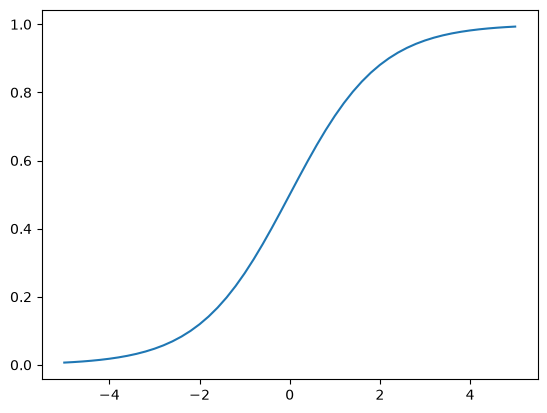

In [81]:
plt.plot(z, sigmoid(z))

In [82]:
def linear_regression(xi):
    result = w0
    
    for j in range(len(w)):
        result = result + xi[j] * w[j]

    return result
    

In [83]:
def logistic_regression(xi):
    score = w0
    for j in range(len(w)):
        score = score + xi[j] * w[j]
        
    result = sigmoid(score)
    return result

## Train logistic regression

In [84]:
from sklearn.linear_model import LogisticRegression

In [85]:
model = LogisticRegression()

In [86]:
model.fit(X_train, y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [87]:
model.coef_

array([[ 2.91391965e-01, -1.35539521e-01, -2.28706742e-01,
         3.04150354e-02, -1.03269333e-01,  7.03306115e-02,
        -9.18300801e-02, -5.13548293e-02, -2.22520038e-02,
        -5.06022941e-02, -3.29478536e-01,  3.48454318e-01,
        -9.18300801e-02, -2.45668372e-01,  5.18584120e-02,
         1.20955662e-01,  7.24515879e-02, -9.18300801e-02,
        -5.34758057e-02,  2.66240846e-01, -9.18300801e-02,
        -2.47265064e-01, -2.58319999e-01,  1.85465702e-01,
        -1.01834256e-01,  2.89799584e-02, -6.46098091e-02,
        -3.42091025e-02,  1.62130181e-01, -1.36165567e-01,
         5.18584120e-02, -1.24712710e-01,  1.85091985e-01,
        -1.04764374e-01, -9.18300801e-02,  1.23740156e-01,
        -6.91960259e-02, -9.18300801e-02,  8.81718081e-02,
         2.43566130e-01, -9.18300801e-02, -2.24590347e-01,
        -6.88220010e-02,  3.36545917e-04]])

In [88]:
model.intercept_

array([-0.07301103])

In [89]:
model.predict(X_train) #hard predictions

array([0, 1, 1, ..., 0, 0, 1], shape=(4225,))

In [90]:
model.predict_proba(X_train) #prob_0, prob_1

array([[0.89939084, 0.10060916],
       [0.28828017, 0.71171983],
       [0.34367759, 0.65632241],
       ...,
       [0.5442238 , 0.4557762 ],
       [0.93950426, 0.06049574],
       [0.28801708, 0.71198292]], shape=(4225, 2))

In [91]:
y_pred = model.predict_proba(X_val)[:,1]
y_pred

array([0.01011057, 0.18140745, 0.20208864, ..., 0.1312514 , 0.81488158,
       0.84610979], shape=(1409,))

In [92]:
churn_decision = y_pred >=0.5
churn_decision

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [93]:
df_val[churn_decision].customerid

3       8433-WXGNA
8       3440-JPSCL
12      7228-OMTPN
19      6711-FLDFB
24      2612-RANWT
           ...    
1397    5976-JCJRH
1398    2034-CGRHZ
1399    5276-KQWHG
1407    6521-YYTYI
1408    3049-SOLAY
Name: customerid, Length: 306, dtype: str

## Accuracy

In [94]:
y_val

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [95]:
churn_decision.astype(int)

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [96]:
(y_val == churn_decision).mean()

np.float64(0.8055358410220014)

In [97]:
df_pred = pd.DataFrame()

In [98]:
df_pred['prob'] = y_pred

In [99]:
df_pred['pred'] = churn_decision.astype(int)
df_pred['actual'] = y_val

In [100]:
df_pred

,prob,pred,actual
0,0.010111,0,0
1,0.181407,0,0
2,0.202089,0,0
3,0.577662,1,1
4,0.218652,0,0
...,...,...,...
1404,0.252516,0,0
1405,0.041529,0,1
1406,0.131251,0,0
1407,0.814882,1,1


In [101]:
df_pred['coorect'] = df_pred.pred == df_pred.actual

In [102]:
df_pred

,prob,pred,actual,coorect
0,0.010111,0,0,True
1,0.181407,0,0,True
2,0.202089,0,0,True
3,0.577662,1,1,True
4,0.218652,0,0,True
...,...,...,...,...
1404,0.252516,0,0,True
1405,0.041529,0,1,False
1406,0.131251,0,0,True
1407,0.814882,1,1,True


In [103]:
df_pred.coorect.astype(int).mean()

np.float64(0.8055358410220014)

In [104]:
df_pred.coorect.mean()

np.float64(0.8055358410220014)

## Model Interpretation

In [105]:
dv.get_feature_names_out()

array(['contract=Month-to-month', 'contract=One year',
       'contract=Two year', 'dependents=No', 'dependents=Yes',
       'deviceprotection=No', 'deviceprotection=No internet service',
       'deviceprotection=Yes', 'gender=Female', 'gender=Male',
       'internetservice=DSL', 'internetservice=Fiber optic',
       'internetservice=No', 'multiplelines=No',
       'multiplelines=No phone service', 'multiplelines=Yes',
       'onlinebackup=No', 'onlinebackup=No internet service',
       'onlinebackup=Yes', 'onlinesecurity=No',
       'onlinesecurity=No internet service', 'onlinesecurity=Yes',
       'paperlessbilling=No', 'paperlessbilling=Yes', 'partner=No',
       'partner=Yes', 'paymentmethod=Bank transfer (automatic)',
       'paymentmethod=Credit card (automatic)',
       'paymentmethod=Electronic check', 'paymentmethod=Mailed check',
       'phoneservice=No', 'phoneservice=Yes', 'seniorcitizen',
       'streamingmovies=No', 'streamingmovies=No internet service',
       'streaming

In [106]:
model.coef_

array([[ 2.91391965e-01, -1.35539521e-01, -2.28706742e-01,
         3.04150354e-02, -1.03269333e-01,  7.03306115e-02,
        -9.18300801e-02, -5.13548293e-02, -2.22520038e-02,
        -5.06022941e-02, -3.29478536e-01,  3.48454318e-01,
        -9.18300801e-02, -2.45668372e-01,  5.18584120e-02,
         1.20955662e-01,  7.24515879e-02, -9.18300801e-02,
        -5.34758057e-02,  2.66240846e-01, -9.18300801e-02,
        -2.47265064e-01, -2.58319999e-01,  1.85465702e-01,
        -1.01834256e-01,  2.89799584e-02, -6.46098091e-02,
        -3.42091025e-02,  1.62130181e-01, -1.36165567e-01,
         5.18584120e-02, -1.24712710e-01,  1.85091985e-01,
        -1.04764374e-01, -9.18300801e-02,  1.23740156e-01,
        -6.91960259e-02, -9.18300801e-02,  8.81718081e-02,
         2.43566130e-01, -9.18300801e-02, -2.24590347e-01,
        -6.88220010e-02,  3.36545917e-04]])

In [107]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=Month-to-month': np.float64(0.291),
 'contract=One year': np.float64(-0.136),
 'contract=Two year': np.float64(-0.229),
 'dependents=No': np.float64(0.03),
 'dependents=Yes': np.float64(-0.103),
 'deviceprotection=No': np.float64(0.07),
 'deviceprotection=No internet service': np.float64(-0.092),
 'deviceprotection=Yes': np.float64(-0.051),
 'gender=Female': np.float64(-0.022),
 'gender=Male': np.float64(-0.051),
 'internetservice=DSL': np.float64(-0.329),
 'internetservice=Fiber optic': np.float64(0.348),
 'internetservice=No': np.float64(-0.092),
 'multiplelines=No': np.float64(-0.246),
 'multiplelines=No phone service': np.float64(0.052),
 'multiplelines=Yes': np.float64(0.121),
 'onlinebackup=No': np.float64(0.072),
 'onlinebackup=No internet service': np.float64(-0.092),
 'onlinebackup=Yes': np.float64(-0.053),
 'onlinesecurity=No': np.float64(0.266),
 'onlinesecurity=No internet service': np.float64(-0.092),
 'onlinesecurity=Yes': np.float64(-0.247),
 'paperlessbilling

In [108]:
small = ['contract', 'tenure', 'monthlycharges']
df_train[small].iloc[:10].to_dict(orient='records')

[{'contract': 'Two year', 'tenure': 72, 'monthlycharges': 115.5},
 {'contract': 'Month-to-month', 'tenure': 10, 'monthlycharges': 95.25},
 {'contract': 'Month-to-month', 'tenure': 5, 'monthlycharges': 75.55},
 {'contract': 'Month-to-month', 'tenure': 5, 'monthlycharges': 80.85},
 {'contract': 'Two year', 'tenure': 18, 'monthlycharges': 20.1},
 {'contract': 'Month-to-month', 'tenure': 4, 'monthlycharges': 30.5},
 {'contract': 'Month-to-month', 'tenure': 1, 'monthlycharges': 75.1},
 {'contract': 'Month-to-month', 'tenure': 1, 'monthlycharges': 70.3},
 {'contract': 'Two year', 'tenure': 72, 'monthlycharges': 19.75},
 {'contract': 'Month-to-month', 'tenure': 6, 'monthlycharges': 109.9}]

In [109]:
dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

In [110]:
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

In [111]:
dv_small.get_feature_names_out()

array(['contract=Month-to-month', 'contract=One year',
       'contract=Two year', 'monthlycharges', 'tenure'], dtype=object)

In [112]:
X_train_small = dv_small.transform(dicts_train_small)

In [113]:
model_small = LogisticRegression()
model_small.fit(X_train_small, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [114]:
w0 = model_small.intercept_[0]
w = model_small.coef_[0]
w.round(3)

array([ 0.971, -0.024, -0.948,  0.027, -0.036])

In [115]:
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

{'contract=Month-to-month': np.float64(0.971),
 'contract=One year': np.float64(-0.024),
 'contract=Two year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

## USING THE MODEL

In [116]:
df_full_train

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,5442-PPTJY,Male,0,Yes,Yes,12,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.70,258.35,0
1,6261-RCVNS,Female,0,No,No,42,Yes,No,DSL,Yes,...,Yes,Yes,No,Yes,One year,No,Credit card (automatic),73.90,3160.55,1
2,2176-OSJUV,Male,0,Yes,No,71,Yes,Yes,DSL,Yes,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),65.15,4681.75,0
3,6161-ERDGD,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,No,Electronic check,85.45,6300.85,0
4,2364-UFROM,Male,0,No,No,30,Yes,No,DSL,Yes,...,No,Yes,Yes,No,One year,No,Electronic check,70.40,2044.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,0781-LKXBR,Male,1,No,No,9,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.50,918.60,1
5630,3507-GASNP,Male,0,No,Yes,60,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.95,1189.90,0
5631,8868-WOZGU,Male,0,No,No,28,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,105.70,2979.50,1
5632,1251-KRREG,Male,0,No,No,2,Yes,Yes,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,54.40,114.10,1


In [117]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

In [118]:
dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

In [119]:
model = LogisticRegression()
model.fit(X_full_train, y_full_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [120]:
dicts_test = df_test[categorical + numerical].to_dict(orient='records')
X_test = dv.transform(dicts_test)
y_pred = model.predict_proba(X_test)[:,1]
y_pred

array([0.05183406, 0.13352935, 0.3234217 , ..., 0.0064232 , 0.20740978,
       0.62727405], shape=(1409,))

In [121]:
churn_decision = y_pred >= 0.50

In [122]:
(churn_decision == y_test).mean()

np.float64(0.8097941802696949)

In [123]:
customer = dicts_test[10]
customer

{'gender': 'Male',
 'seniorcitizen': 1,
 'partner': 'Yes',
 'dependents': 'Yes',
 'phoneservice': 'Yes',
 'multiplelines': 'No',
 'internetservice': 'Fiber optic',
 'onlinesecurity': 'No',
 'onlinebackup': 'Yes',
 'deviceprotection': 'No',
 'techsupport': 'No',
 'streamingtv': 'Yes',
 'streamingmovies': 'Yes',
 'contract': 'Month-to-month',
 'paperlessbilling': 'Yes',
 'paymentmethod': 'Mailed check',
 'tenure': 32,
 'totalcharges': 2861.45}

In [124]:
X_small = dv.transform([customer])
model.predict_proba(X_small)

array([[0.50992346, 0.49007654]])

In [125]:
y_test[10]

np.int64(0)

In [126]:
y_test[-1]

np.int64(1)

In [127]:
customer = dicts_test[-1]
customer

{'gender': 'Female',
 'seniorcitizen': 0,
 'partner': 'Yes',
 'dependents': 'Yes',
 'phoneservice': 'Yes',
 'multiplelines': 'Yes',
 'internetservice': 'Fiber optic',
 'onlinesecurity': 'Yes',
 'onlinebackup': 'No',
 'deviceprotection': 'Yes',
 'techsupport': 'No',
 'streamingtv': 'Yes',
 'streamingmovies': 'Yes',
 'contract': 'Month-to-month',
 'paperlessbilling': 'Yes',
 'paymentmethod': 'Electronic check',
 'tenure': 17,
 'totalcharges': 1743.5}

In [128]:
X_small = dv.transform([customer])
model.predict_proba(X_small)

array([[0.37272595, 0.62727405]])

## Evaluation

In [129]:
len(y_val)

1409

In [130]:
(y_val == churn_decision).sum()

np.int64(867)

In [131]:
(y_val == churn_decision).mean()

np.float64(0.6153300212916962)

In [132]:
thresholds = np.linspace(0,1,21)
thresholds

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ])

In [133]:
scores = []

for t in thresholds:
    churn_decision = (y_pred >= t)
    score = (y_val == churn_decision).mean()
    print(t, score)
    scores.append(score)

0.0 0.2739531582682754
0.05 0.4038325053229241
0.1 0.45493257629524486
0.15000000000000002 0.48403122782114977
0.2 0.5003548616039745
0.25 0.5294535131298793
0.30000000000000004 0.5415188076650106
0.35000000000000003 0.5592618878637331
0.4 0.5777146912704045
0.45 0.5933286018452804
0.5 0.6153300212916962
0.55 0.6288147622427254
0.6000000000000001 0.6493967352732435
0.65 0.6721078779276083
0.7000000000000001 0.6926898509581263
0.75 0.7118523775727467
0.8 0.7210787792760823
0.8500000000000001 0.7260468417317246
0.9 0.7260468417317246
0.9500000000000001 0.7260468417317246
1.0 0.7260468417317246


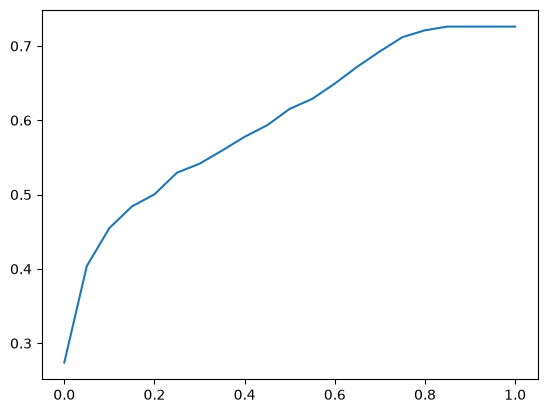

In [134]:
plt.plot(thresholds, scores)

In [135]:
from sklearn.metrics import accuracy_score

In [136]:
accuracy_score(y_val,y_pred >= 0.5)

0.6153300212916962

In [137]:
scores = []

for t in thresholds:
    score = accuracy_score(y_val,y_pred >= t)
    print(t, score)
    scores.append(score)

0.0 0.2739531582682754
0.05 0.4038325053229241
0.1 0.45493257629524486
0.15000000000000002 0.48403122782114977
0.2 0.5003548616039745
0.25 0.5294535131298793
0.30000000000000004 0.5415188076650106
0.35000000000000003 0.5592618878637331
0.4 0.5777146912704045
0.45 0.5933286018452804
0.5 0.6153300212916962
0.55 0.6288147622427254
0.6000000000000001 0.6493967352732435
0.65 0.6721078779276083
0.7000000000000001 0.6926898509581263
0.75 0.7118523775727467
0.8 0.7210787792760823
0.8500000000000001 0.7260468417317246
0.9 0.7260468417317246
0.9500000000000001 0.7260468417317246
1.0 0.7260468417317246


In [138]:
from collections import Counter

In [139]:
Counter(y_pred >=1.0)

Counter({np.False_: 1409})

In [140]:
Counter(y_pred >= 0.7)

Counter({np.False_: 1310, np.True_: 99})

## Confusion table

In [141]:
actual_positive = (y_val ==1)
actual_negative = (y_val ==0)
t = 0.5
predicted_positive = (y_pred >= t)
predicted_negative = (y_pred < t)

In [142]:
tp = (predicted_positive & actual_positive).sum()
tn = (predicted_negative & actual_negative).sum()
fn = (predicted_negative & actual_positive).sum()
fp = (predicted_positive & actual_negative).sum()
tp, tn, fn, fp

(np.int64(85), np.int64(782), np.int64(301), np.int64(241))

In [143]:
confusion_matrix = np.array([
    [tn,fp],
    [tp, fn]
])
confusion_matrix

array([[782, 241],
       [ 85, 301]])

# Precision & Recall

In [144]:
accuracy = (tp + tn) / (tp+tn+fp+fn)
accuracy

np.float64(0.6153300212916962)

In [145]:
precision = (tp / (tp + fp))
precision

np.float64(0.2607361963190184)

In [146]:
recall = (tp/ (tp+fn))
recall

np.float64(0.22020725388601037)

## Roc curve

In [147]:
#minimize false negative
#maximize true positive

In [148]:
tpr = tp/(tp+fn)
tpr

np.float64(0.22020725388601037)

In [149]:
fpr = fp/(fp+tn) 
fpr

np.float64(0.23558162267839688)

In [150]:
thresholds = np.linspace(0,1,101)

In [151]:
scores = []

for t in thresholds:
    actual_positive = (y_val ==1)
    actual_negative = (y_val ==0)
    
    predicted_positive = (y_pred >= t)
    predicted_negative = (y_pred < t)
    tp = (predicted_positive & actual_positive).sum()
    tn = (predicted_negative & actual_negative).sum()
    
    fn = (predicted_negative & actual_positive).sum()
    fp = (predicted_positive & actual_negative).sum()

    scores.append((t, tp, fp, fn, tn))

In [152]:
scores

[(np.float64(0.0), np.int64(386), np.int64(1023), np.int64(0), np.int64(0)),
 (np.float64(0.01), np.int64(359), np.int64(918), np.int64(27), np.int64(105)),
 (np.float64(0.02), np.int64(332), np.int64(856), np.int64(54), np.int64(167)),
 (np.float64(0.03), np.int64(323), np.int64(818), np.int64(63), np.int64(205)),
 (np.float64(0.04), np.int64(312), np.int64(781), np.int64(74), np.int64(242)),
 (np.float64(0.05), np.int64(298), np.int64(752), np.int64(88), np.int64(271)),
 (np.float64(0.06), np.int64(290), np.int64(724), np.int64(96), np.int64(299)),
 (np.float64(0.07),
  np.int64(279),
  np.int64(687),
  np.int64(107),
  np.int64(336)),
 (np.float64(0.08),
  np.int64(262),
  np.int64(669),
  np.int64(124),
  np.int64(354)),
 (np.float64(0.09),
  np.int64(255),
  np.int64(646),
  np.int64(131),
  np.int64(377)),
 (np.float64(0.1), np.int64(246), np.int64(628), np.int64(140), np.int64(395)),
 (np.float64(0.11),
  np.int64(237),
  np.int64(609),
  np.int64(149),
  np.int64(414)),
 (np.fl

In [153]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns = columns)
df_scores

,threshold,tp,fp,fn,tn
0,0.00,386,1023,0,0
1,0.01,359,918,27,105
2,0.02,332,856,54,167
3,0.03,323,818,63,205
4,0.04,312,781,74,242
...,...,...,...,...,...
96,0.96,0,0,386,1023
97,0.97,0,0,386,1023
98,0.98,0,0,386,1023
99,0.99,0,0,386,1023


In [154]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [155]:
df_scores

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,386,1023,0,0,1.000000,1.000000
1,0.01,359,918,27,105,0.930052,0.897361
2,0.02,332,856,54,167,0.860104,0.836755
3,0.03,323,818,63,205,0.836788,0.799609
4,0.04,312,781,74,242,0.808290,0.763441
...,...,...,...,...,...,...,...
96,0.96,0,0,386,1023,0.000000,0.000000
97,0.97,0,0,386,1023,0.000000,0.000000
98,0.98,0,0,386,1023,0.000000,0.000000
99,0.99,0,0,386,1023,0.000000,0.000000


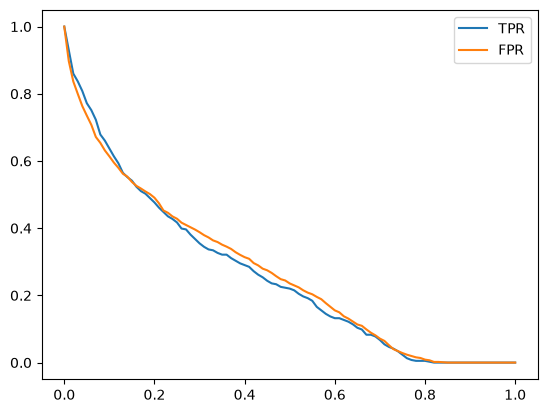

In [156]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

In [157]:
#Target: tpr lower, FPR higher

In [158]:
 ## Random model

In [160]:
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size = len(y_val))

In [161]:
y_rand.round(3)

array([0.417, 0.72 , 0.   , ..., 0.774, 0.334, 0.089], shape=(1409,))

In [165]:
((y_rand >= 0.5 ) == y_val).mean()

np.float64(0.5017743080198722)

In [166]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []
    thresholds = np.linspace(0,1,101)

    for t in thresholds:
        actual_positive = (y_val ==1)
        actual_negative = (y_val ==0)
        
        predicted_positive = (y_pred >= t)
        predicted_negative = (y_pred < t)
        tp = (predicted_positive & actual_positive).sum()
        tn = (predicted_negative & actual_negative).sum()
        
        fn = (predicted_negative & actual_positive).sum()
        fp = (predicted_positive & actual_negative).sum()
    
        scores.append((t, tp, fp, fn, tn))
        
    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns = columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores

In [167]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

In [168]:
df_rand

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,386,1023,0,0,1.000000,1.000000
1,0.01,382,1013,4,10,0.989637,0.990225
2,0.02,379,993,7,30,0.981865,0.970674
3,0.03,375,979,11,44,0.971503,0.956989
4,0.04,372,969,14,54,0.963731,0.947214
...,...,...,...,...,...,...,...
96,0.96,14,41,372,982,0.036269,0.040078
97,0.97,11,36,375,987,0.028497,0.035191
98,0.98,8,19,378,1004,0.020725,0.018573
99,0.99,6,7,380,1016,0.015544,0.006843


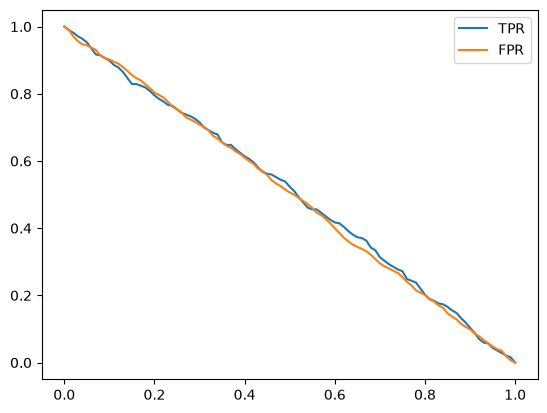

In [170]:
plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')
plt.legend()

In [171]:
## ideal model

In [172]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [173]:
y_ideal = np.repeat([0,1], [ num_neg, num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [175]:
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [177]:
((y_ideal_pred >= 0.726) == y_ideal).mean()

np.float64(1.0)

In [178]:
1- y_val.mean()

np.float64(0.7260468417317246)

In [179]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

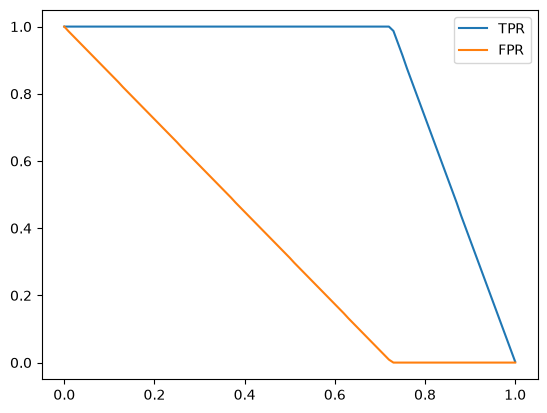

In [182]:
plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR')

plt.legend()

In [183]:
## Plot everything toghether

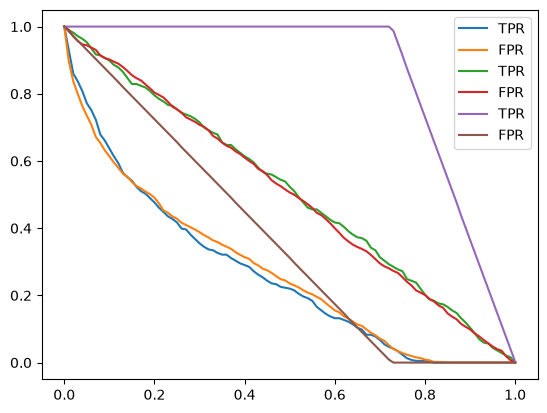

In [184]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')

plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR')

plt.legend()

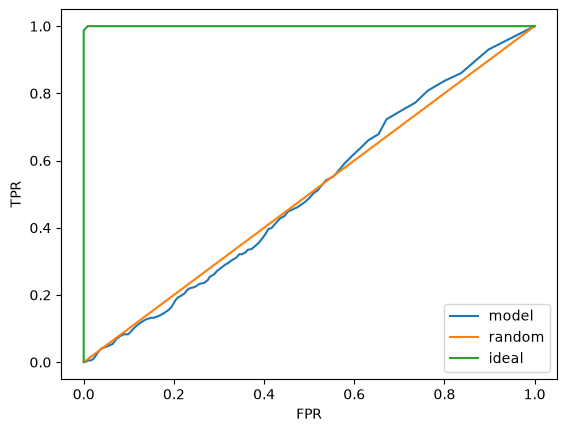

In [189]:
plt.plot(df_scores.fpr, df_scores['tpr'], label='model')
plt.plot(df_rand.fpr, df_rand['fpr'], label='random')
plt.plot(df_ideal.fpr, df_ideal['tpr'], label='ideal')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

In [190]:
##ROC con SKLEARN

In [191]:
from sklearn.metrics import roc_curve

In [192]:
roc_curve(y_val, y_pred)

(array([0.00000000e+00, 9.77517107e-04, 2.93255132e-03, 2.93255132e-03,
        8.79765396e-03, 8.79765396e-03, 1.56402737e-02, 1.56402737e-02,
        1.95503421e-02, 1.95503421e-02, 2.15053763e-02, 2.15053763e-02,
        2.34604106e-02, 2.34604106e-02, 2.54154448e-02, 2.54154448e-02,
        3.03030303e-02, 3.03030303e-02, 3.22580645e-02, 3.22580645e-02,
        3.61681329e-02, 3.61681329e-02, 3.91006843e-02, 3.91006843e-02,
        4.10557185e-02, 4.10557185e-02, 4.39882698e-02, 4.39882698e-02,
        5.27859238e-02, 5.27859238e-02, 5.96285435e-02, 5.96285435e-02,
        6.45161290e-02, 6.45161290e-02, 6.54936461e-02, 6.54936461e-02,
        6.64711632e-02, 6.64711632e-02, 7.33137830e-02, 7.33137830e-02,
        7.91788856e-02, 7.91788856e-02, 8.01564027e-02, 8.01564027e-02,
        8.11339198e-02, 8.11339198e-02, 8.30889541e-02, 8.30889541e-02,
        1.00684262e-01, 1.00684262e-01, 1.01661779e-01, 1.01661779e-01,
        1.03616813e-01, 1.03616813e-01, 1.04594330e-01, 1.045943

In [193]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

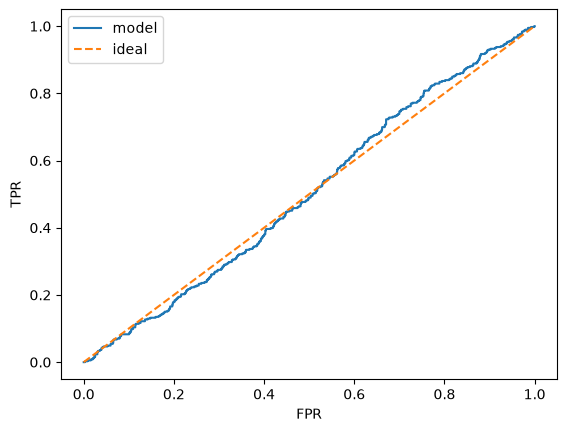

In [196]:
plt.plot(fpr, tpr, label='model')
plt.plot([0,1], [0,1], label='ideal', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

## AUC

In [197]:
#AREA UNDER THE ROC CURVE

In [198]:
from sklearn.metrics import auc

In [201]:
auc(fpr, tpr) #auc((x, y)

0.5031794630240226

In [202]:
auc(df_scores.fpr, df_scores.tpr)

0.5034251085145285

In [203]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [204]:
from sklearn.metrics import roc_auc_score

In [205]:
roc_auc_score(y_val, y_pred)

0.5031794630240226

## CROSS validation

In [238]:
def train(df, y, C=1.0):
    dicts = df[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse= False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=10000)
    model.fit(X_train, y_train)

    return dv, model

In [239]:
dv, model = train(df_train, y_train)

In [240]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [241]:
y_pred = predict(df_val, dv, model)
y_pred

array([0.16641829, 0.00486941, 0.67234737, 0.07443727, 0.59192788,
       0.30683068, 0.29677978, 0.22503916, 0.00282492, 0.08583049,
       0.05057762, 0.01257749, 0.48561738, 0.73722684, 0.32764209,
       0.19906359, 0.65262065, 0.25577634, 0.27474726, 0.03014484,
       0.68929547, 0.02440104, 0.0029672 , 0.51335376, 0.75381272,
       0.08279345, 0.73109944, 0.02890436, 0.66732412, 0.00979814,
       0.03701478, 0.00864901, 0.43797634, 0.55480205, 0.14038986,
       0.03195765, 0.52635282, 0.15411288, 0.74554323, 0.63882373,
       0.33519706, 0.28232046, 0.73341543, 0.00701407, 0.00213957,
       0.57909638, 0.41617675, 0.31163528, 0.09127974, 0.48857697,
       0.00737564, 0.00640741, 0.54501372, 0.61059472, 0.19767782,
       0.08489448, 0.00470134, 0.43579169, 0.01888662, 0.00401623,
       0.02086609, 0.68784746, 0.27427046, 0.06192878, 0.64885915,
       0.03373489, 0.73739289, 0.07670398, 0.18116666, 0.01663778,
       0.42672554, 0.39062067, 0.50509132, 0.18808121, 0.70485

In [242]:
from sklearn.model_selection import KFold

In [243]:
kfold = KFold(n_splits =10, shuffle=True, random_state=1)

In [244]:
train_idx, val_idx = next(kfold.split(df_full_train))

In [245]:
len(df_full_train), len(train_idx), len(val_idx)

(5634, 5070, 564)

In [246]:
df_train = df_full_train.iloc[train_idx]
df_val = df_full_train.iloc[val_idx]

In [252]:
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.churn.values
    y_val = df_val.churn.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

In [253]:
!pip install tqdm

In [254]:
from tqdm.auto import tqdm

In [255]:
scores

[0.8499435459504159,
 0.8424504950495049,
 0.8584954238160889,
 0.833272981647601,
 0.8246743176178659,
 0.8414585414585415,
 0.8430804298274178,
 0.8255297280202404,
 0.8459315251222767,
 0.8612651675573929]

In [256]:
np.mean(scores), np.std(scores)

(np.float64(0.8426102156067345), np.float64(0.011693384023643153))

In [263]:
n_splits = 5

for C in [0.001, 0.01, 0.1, 0.5, 1,5,10]:
    scores = []

    kfold = KFold(n_splits =n_splits, shuffle=True, random_state=1)

    for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=n_splits):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.churn.values
        y_val = df_val.churn.values
    
        dv, model = train(df_train, y_train, C)
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print(C, np.mean(scores), np.std(scores))

  0%|          | 0/5 [00:00<?, ?it/s]

0.001 0.8274203336416077 0.012961938706509083


  0%|          | 0/5 [00:00<?, ?it/s]

0.01 0.8408202297985581 0.008590263322333067


  0%|          | 0/5 [00:00<?, ?it/s]

0.1 0.8419482694648526 0.00720508364848755


  0%|          | 0/5 [00:00<?, ?it/s]

0.5 0.841965151294664 0.0069488263672831145


  0%|          | 0/5 [00:00<?, ?it/s]

1 0.8419479014926724 0.006916838985219342


  0%|          | 0/5 [00:00<?, ?it/s]

5 0.8418826525703007 0.006891602781624175


  0%|          | 0/5 [00:00<?, ?it/s]

10 0.8418979304360746 0.006887780707145859


In [265]:
dv, model = train(df_full_train, df_full_train.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)
    
auc = roc_auc_score(y_test, y_pred)
auc

ValueError: Found input variables with inconsistent numbers of samples: [5634, 4508]